# ISY503 — Assessment 3: Data Loading & Exploratory Data Analysis (EDA)
**Project:** NLP Sentiment Analysis on Amazon Product Reviews (Hugging Face)  
**Branch:** `carlos-data-eda` | **Owner:** Carlos  
**Team:** Carlos (Data + EDA) · Heidy (Preprocessing + Tokenizer) · Renato (Model + Fine-Tuning) · Oscar (Evaluation + Error Analysis + App)

### Objective & Core Question
This notebook covers Steps 1–3 of the team workflow (**Data Loading**, **Initial Inspection + EDA**, and **Cleaning / Duplicates / Outliers Recommendations**) on the **8,000 labeled reviews** across four Amazon product domains (`books`, `dvd`, `electronics`, `kitchen_&_housewares`). Unlabeled reviews are excluded from v1 per the group agreement.

**Core question to answer for the team & presentation:**
> *What data do we have, what problems does it present, and what technical decisions are justified by the EDA?*

## 1. Setup & Configuration
Configure paths so the notebook runs seamlessly in all machines in the repo root.

In [29]:
import html
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

# Auto-detect dataset location (repo-relative first, then Carlos's local OneDrive path)
CANDIDATE_DATA_DIRS = [
    Path("../data/raw"),
    Path("data/raw"),
    Path("../sorted_data_acl"),
    Path("sorted_data_acl"),
    Path("/Users/andresvargas/Library/CloudStorage/OneDrive-MyLearn/ISY503/Assesment 3/sorted_data_acl"),
]

DATA_DIR = next((p for p in CANDIDATE_DATA_DIRS if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not locate 'data'. Set DATA_DIR manually to the folder containing books/, dvd/, electronics/, and kitchen_&_housewares/."
    )

REPO_ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path.cwd().resolve()
FIG_DIR = REPO_ROOT / "outputs" / "eda_figures"
PROCESSED_DIR = REPO_ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

DOMAINS = ["books", "dvd", "electronics", "kitchen_&_housewares"]
SENTIMENTS = {"positive": 1, "negative": 0}
XML_TAGS = [
    "unique_id",
    "asin",
    "product_name",
    "product_type",
    "helpful",
    "rating",
    "title",
    "date",
    "reviewer",
    "reviewer_location",
    "review_text",
]

print(f"DATA_DIR:      {DATA_DIR.resolve()}")
print(f"FIG_DIR:       {FIG_DIR}")
print(f"PROCESSED_DIR: {PROCESSED_DIR}")

DATA_DIR:      /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/data/raw
FIG_DIR:       /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/outputs/eda_figures
PROCESSED_DIR: /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/data/processed


## 2. Robust Data Loading & Parsing
The raw `.review` files use XML-like `<review>` blocks but are **not valid strict XML**:
- No single root XML element.
- Unescaped `&` characters in product names and review text.
- HTML entities (e.g., `&quot;`, `&amp;`) requiring `html.unescape()`.

We parse all 8 labeled files with a tolerant regex extractor (`utf-8` with `latin-1` fallback) and log per-file diagnostics.

In [30]:
ENTITY_PATTERN = re.compile(r"&(?:quot|amp|lt|gt|apos|#\d+|#x[0-9a-fA-F]+);")
REVIEW_BLOCK_PATTERN = re.compile(r"<review>(.*?)</review>", flags=re.DOTALL)
TAG_PATTERNS = {
    tag: re.compile(rf"<{tag}>(.*?)</{tag}>", flags=re.DOTALL) for tag in XML_TAGS
}


def load_labeled_reviews(data_dir: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    records = []
    file_logs = []

    for domain in DOMAINS:
        for sentiment, label in SENTIMENTS.items():
            file_path = data_dir / domain / f"{sentiment}.review"
            if not file_path.exists():
                raise FileNotFoundError(f"Missing expected file: {file_path}")

            raw_bytes = file_path.read_bytes()
            encoding_used = "utf-8"
            try:
                raw_text = raw_bytes.decode("utf-8")
            except UnicodeDecodeError:
                encoding_used = "latin-1"
                raw_text = raw_bytes.decode("latin-1")

            blocks = REVIEW_BLOCK_PATTERN.findall(raw_text)
            html_entity_rows = 0

            for block in blocks:
                row = {
                    "domain": domain,
                    "sentiment": sentiment,
                    "label": label,
                    "source_file": f"{domain}/{sentiment}.review",
                }
                for tag, pat in TAG_PATTERNS.items():
                    match = pat.search(block)
                    row[tag] = match.group(1).strip() if match else ""

                if ENTITY_PATTERN.search(row["title"] + " " + row["review_text"]):
                    html_entity_rows += 1

                row["title_clean"] = re.sub(r"\s+", " ", html.unescape(row["title"])).strip()
                row["review_text_clean"] = re.sub(
                    r"\s+", " ", html.unescape(row["review_text"])
                ).strip()
                row["full_text"] = (
                    f"{row['title_clean']}. {row['review_text_clean']}".strip(". ")
                    if row["title_clean"]
                    else row["review_text_clean"]
                )
                records.append(row)

            file_logs.append(
                {
                    "domain": domain,
                    "sentiment": sentiment,
                    "reviews_parsed": len(blocks),
                    "encoding_used": encoding_used,
                    "rows_with_html_entities": html_entity_rows,
                    "file_size_mb": round(len(raw_bytes) / (1024 * 1024), 2),
                }
            )

    df = pd.DataFrame(records)
    df["rating_num"] = pd.to_numeric(df["rating"], errors="coerce")
    df["review_year"] = (
        df["date"].str.extract(r"((?:19|20)\d{2})", expand=False).astype("Int64")
    )
    return df, pd.DataFrame(file_logs)


df, parse_log_df = load_labeled_reviews(DATA_DIR)
print(f"Total labeled reviews loaded: {len(df):,}")
display(parse_log_df)

Total labeled reviews loaded: 8,000


,domain,sentiment,reviews_parsed,encoding_used,rows_with_html_entities,file_size_mb
0,books,positive,1000,utf-8,64,1.44
1,books,negative,1000,utf-8,36,1.47
2,dvd,positive,1000,utf-8,14,1.62
3,dvd,negative,1000,utf-8,16,1.52
4,electronics,positive,1000,utf-8,11,1.05
5,electronics,negative,1000,utf-8,11,1.06
6,kitchen_&_housewares,positive,1000,utf-8,15,0.97
7,kitchen_&_housewares,negative,1000,utf-8,17,0.97


In [31]:
display(df[["domain", "sentiment", "label", "rating_num", "date", "title_clean", "review_text_clean"]].head(5))

,domain,sentiment,label,rating_num,date,title_clean,review_text_clean
0,books,positive,1,5.0,"July 1, 2006",One of the best Crichton novels,Sphere by Michael Crichton is an excellant nov...
1,books,positive,1,4.0,"November 6, 2002",The Medicine of the Future,Dr. Oz is an accomplished heart surgeon in the...
2,books,positive,1,5.0,"June 13, 2006",Beautiful!,The most gorgeous artwork in comic books. Cont...
3,books,positive,1,4.0,"November 2, 2006",For lovers of Robicheaux,This book is for lovers of Robicheaux. His dem...
4,books,positive,1,5.0,"October 6, 2006",Excellent and broad survey of the development ...,This is going to be a short and sweet review b...


This is an example of HTML entities detected in the data

In [32]:
# Table of HTML entities detected and real before/after cleaning examples
from collections import Counter

entity_counts = Counter()
entity_examples = {}

for _, r in df.iterrows():
    raw_combined = f"{r['title']} {r['review_text']}"
    for m in ENTITY_PATTERN.finditer(raw_combined):
        ent = m.group(0)
        entity_counts[ent] += 1
        if ent not in entity_examples:
            start = max(0, m.start() - 30)
            end = min(len(raw_combined), m.end() + 30)
            before_snip = re.sub(r"\s+", " ", raw_combined[start:end]).strip()
            after_snip = html.unescape(before_snip)
            entity_examples[ent] = (r["domain"], before_snip, after_snip)

html_entity_table = pd.DataFrame(
    [
        {
            "html_entity": ent,
            "decoded_as": html.unescape(ent),
            "occurrences": cnt,
            "sample_domain": entity_examples[ent][0],
            "before_cleaning": f"...{entity_examples[ent][1]}...",
            "after_cleaning": f"...{entity_examples[ent][2]}...",
        }
        for ent, cnt in entity_counts.most_common()
    ]
)

print(f"Unique HTML entities found: {len(html_entity_table)} (total occurrences: {sum(entity_counts.values()):,})")
display(html_entity_table)

Unique HTML entities found: 10 (total occurrences: 578)


,html_entity,decoded_as,occurrences,sample_domain,before_cleaning,after_cleaning
0,&quot;,"""",500,books,...ate from the late 1980's. His &quot;Great W...,"...ate from the late 1980's. His ""Great Work o..."
1,&amp;,&,35,books,...ste with a twist of the class &amp; sophist...,...ste with a twist of the class & sophisticat...
2,&lt;,<,14,books,...the second half of the book &lt;with extra ...,...the second half of the book <with extra emp...
3,&#62;,>,8,electronics,...will be posted on our website.&#62;&#62;&#6...,...will be posted on our website.>>> I bought ...
4,&#8217;,’,6,books,...Bye-bye to Barty&#8217;s biting back-chat I...,...Bye-bye to Barty’s biting back-chat It’s...
5,&#60;,<,6,electronics,...s before buying this device: &#60;&#60;&#60...,...s before buying this device: <<<Although ou...
6,&#9702;,◦,5,kitchen_&_housewares,"...COOKING TEMPERATURES OVER 392&#9702;F."" as ...","...COOKING TEMPERATURES OVER 392◦F."" as well a..."
7,&gt;,>,2,books,...n the last quarter of the book&gt; was comp...,...n the last quarter of the book> was complet...
8,&#8221;,”,1,books,"...! ...""First Grade Takes a Test&#8221; is an...","...! ...""First Grade Takes a Test” is an excel..."
9,&#65279;,﻿,1,books,"..., but it's just not happening &#65279;Mille...","..., but it's just not happening ﻿Millennials ..."


## 3. Domain Distribution, Class Balance & Missing Fields
Verify class balance across domains, star-rating polarity, and missing/empty fields.

In [33]:
balance_ct = pd.crosstab(df["domain"], df["sentiment"], margins=True)
display(balance_ct)

rating_ct = pd.crosstab(df["rating_num"].fillna(-1), df["sentiment"], margins=True)
rating_ct.index.name = "rating (-1 = missing)"
display(rating_ct)

missing_df = pd.DataFrame(
    [
        {
            "field": col,
            "empty_count": int((df[col].fillna("").str.strip() == "").sum()),
            "empty_pct": round((df[col].fillna("").str.strip() == "").mean() * 100, 2),
        }
        for col in XML_TAGS
    ]
).sort_values("empty_count", ascending=False)
display(missing_df)

sentiment,negative,positive,All
domain,,,
books,1000,1000,2000
dvd,1000,1000,2000
electronics,1000,1000,2000
kitchen_&_housewares,1000,1000,2000
All,4000,4000,8000


sentiment,negative,positive,All
rating (-1 = missing),,,
1.0,2421,0,2421
2.0,1579,0,1579
4.0,0,1121,1121
5.0,0,2879,2879
All,4000,4000,8000


,field,empty_count,empty_pct
9,reviewer_location,1325,16.56
4,helpful,1299,16.24
8,reviewer,167,2.09
7,date,1,0.01
0,unique_id,0,0.00
1,asin,0,0.00
2,product_name,0,0.00
3,product_type,0,0.00
5,rating,0,0.00
6,title,0,0.00


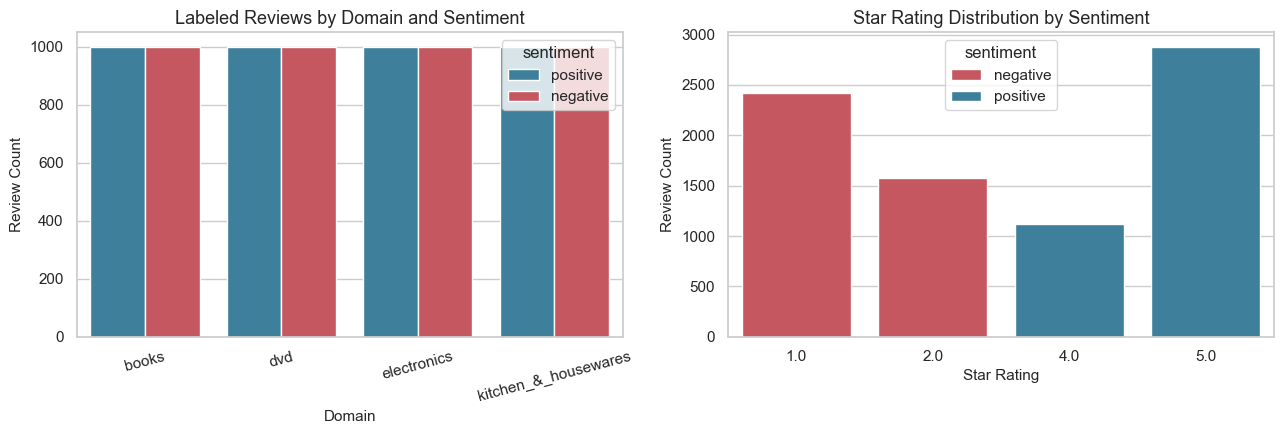

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="domain", hue="sentiment", palette={"positive": "#2E86AB", "negative": "#D64550"}, ax=axes[0])
axes[0].set_title("Labeled Reviews by Domain and Sentiment")
axes[0].set_xlabel("Domain")
axes[0].set_ylabel("Review Count")
axes[0].tick_params(axis="x", rotation=15)

sns.countplot(data=df, x="rating_num", hue="sentiment", palette={"positive": "#2E86AB", "negative": "#D64550"}, ax=axes[1])
axes[1].set_title("Star Rating Distribution by Sentiment")
axes[1].set_xlabel("Star Rating")
axes[1].set_ylabel("Review Count")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig01_balance_and_ratings.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Duplicate & Data-Leakage Analysis
Detect duplicates **before** Train/Validation/Test splitting to prevent train-test leakage.

In [35]:
df["norm_text"] = df["review_text_clean"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
df["norm_full_text"] = df["full_text"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

dup_uid_rows = int(df.duplicated(subset=["unique_id"], keep="first").sum())
dup_text_rows = int(df.duplicated(subset=["norm_text"], keep="first").sum())
dup_full_rows = int(df.duplicated(subset=["norm_full_text"], keep="first").sum())

text_label_nunique = df.groupby("norm_text")["sentiment"].nunique()
conflicting_texts = text_label_nunique[text_label_nunique > 1].index.tolist()

text_domain_nunique = df.groupby("norm_text")["domain"].nunique()
cross_domain_texts = text_domain_nunique[text_domain_nunique > 1].index.tolist()

dup_summary = pd.DataFrame(
    [
        {"check": "Duplicate unique_id (extra rows)", "count": dup_uid_rows},
        {"check": "Duplicate normalized review_text (extra rows)", "count": dup_text_rows},
        {"check": "Duplicate normalized title+text (extra rows)", "count": dup_full_rows},
        {"check": "Unique texts with CONFLICTING sentiment labels", "count": len(conflicting_texts)},
        {"check": "Unique texts appearing across MULTIPLE domains", "count": len(cross_domain_texts)},
    ]
)
display(dup_summary)

if dup_text_rows > 0:
    print("\nSample duplicate review_text entries:")
    display(
        df[df.duplicated(subset=["norm_text"], keep=False)]
        .sort_values("norm_text")[["domain", "sentiment", "rating_num", "unique_id", "title_clean", "review_text_clean"]]
        .head(10)
    )

,check,count
0,Duplicate unique_id (extra rows),0
1,Duplicate normalized review_text (extra rows),148
2,Duplicate normalized title+text (extra rows),146
3,Unique texts with CONFLICTING sentiment labels,0
4,Unique texts appearing across MULTIPLE domains,0



Sample duplicate review_text entries:


,domain,sentiment,rating_num,unique_id,title_clean,review_text_clean
1566,books,negative,1.0,"1419116169:thank_you,_but_no,_thanks:michael_s...","Thank you, but no, thanks","""I have received your new book against the hum..."
1006,books,negative,1.0,"0140444394:thank_you,_but_no,_thanks:michael_s...","Thank you, but no, thanks","""I have received your new book against the hum..."
2692,dvd,positive,5.0,6304696582:film_deserved_of_it's_classic_statu...,Film Deserved of It's Classic Status,"""Stagecoach"" is significant, along with ""Destr..."
2857,dvd,positive,5.0,B000F0UUJ6:film_deserved_of_it's_classic_statu...,Film Deserved of It's Classic Status,"""Stagecoach"" is significant, along with ""Destr..."
3705,dvd,negative,1.0,"B00004WZZA:oh,_those_poor_racists_lost_their_s...","Oh, those poor racists lost their slaves, how ...","(1) Scarlett O'Hara is the least likable ""hero..."
3980,dvd,negative,1.0,"B00004RF96:oh,_those_poor_racists_lost_their_s...","Oh, those poor racists lost their slaves, how ...","(1) Scarlett O'Hara is the least likable ""hero..."
1288,books,negative,2.0,0393027503:don't_waste_your_money...:chris_kau...,Don't waste your money...,...you can waste your time and save your money...
1109,books,negative,2.0,0140143459:don't_waste_your_money...:chris_kau...,Don't waste your money...,...you can waste your time and save your money...
1918,books,negative,2.0,0156013053:a_world_of_boring.__a_raging_sea_of...,A world of boring. A raging sea of boring!,2 stars for decent writing (at least a decent ...
1982,books,negative,2.0,0151005346:a_world_of_boring.__a_raging_sea_of...,A world of boring. A raging sea of boring!,2 stars for decent writing (at least a decent ...


## 5. Text Length Distribution & `max_sequence_length` Justification
Analyze character, word, and approximate subword token lengths (`ceil(words * 1.3)`) overall and per domain to justify `max_length` for Hugging Face tokenization.

In [36]:
df["char_len"] = df["review_text_clean"].str.len()
df["word_len"] = df["review_text_clean"].str.split().str.len()
df["full_word_len"] = df["full_text"].str.split().str.len()
df["approx_tokens"] = np.ceil(df["full_word_len"] * 1.3).astype(int)


def length_summary(series: pd.Series) -> pd.Series:
    return pd.Series(
        {
            "count": int(series.count()),
            "min": int(series.min()),
            "mean": round(float(series.mean()), 1),
            "p50_median": int(np.percentile(series, 50)),
            "p75": int(np.percentile(series, 75)),
            "p90": int(np.percentile(series, 90)),
            "p95": int(np.percentile(series, 95)),
            "p99": int(np.percentile(series, 99)),
            "max": int(series.max()),
        }
    )


overall_len_df = pd.DataFrame(
    {
        "review_text_chars": length_summary(df["char_len"]),
        "review_text_words": length_summary(df["word_len"]),
        "title_plus_text_words": length_summary(df["full_word_len"]),
        "approx_subword_tokens": length_summary(df["approx_tokens"]),
    }
)
display(overall_len_df)

print("\nWord count (title + review_text) by Domain:")
display(df.groupby("domain")["full_word_len"].apply(length_summary).unstack())

trunc_df = pd.DataFrame(
    [
        {
            "max_length_tokens": max_tok,
            "reviews_fitting_pct": round((df["approx_tokens"] <= max_tok).mean() * 100, 2),
            "reviews_truncated_pct": round((df["approx_tokens"] > max_tok).mean() * 100, 2),
            "reviews_truncated_count": int((df["approx_tokens"] > max_tok).sum()),
        }
        for max_tok in [128, 256, 384, 512]
    ]
)
print("\nEstimated Truncation Impact (approx_tokens = ceil(words * 1.3)):")
display(trunc_df)

,review_text_chars,review_text_words,title_plus_text_words,approx_subword_tokens
count,8000.0,8000.0,8000.0,8000.0
min,6.0,1.0,10.0,13.0
mean,752.0,135.3,140.0,182.4
p50_median,488.0,90.0,95.0,124.0
p75,891.0,162.0,167.0,218.0
p90,1625.0,290.0,295.0,384.0
p95,2389.0,417.0,423.0,550.0
p99,4264.0,739.0,746.0,970.0
max,21141.0,3393.0,3397.0,4417.0



Word count (title + review_text) by Domain:


,count,min,mean,p50_median,p75,p90,p95,p99,max
domain,,,,,,,,,
books,2000.0,12.0,177.7,116.0,214.0,389.0,530.0,940.0,3397.0
dvd,2000.0,10.0,171.8,115.0,213.0,382.0,492.0,895.0,1473.0
electronics,2000.0,10.0,113.9,82.0,139.0,229.0,323.0,560.0,1008.0
kitchen_&_housewares,2000.0,11.0,96.4,73.0,119.0,191.0,242.0,434.0,1005.0



Estimated Truncation Impact (approx_tokens = ceil(words * 1.3)):


,max_length_tokens,reviews_fitting_pct,reviews_truncated_pct,reviews_truncated_count
0,128,51.98,48.02,3842
1,256,80.34,19.66,1573
2,384,90.00,10.00,800
3,512,94.09,5.91,473


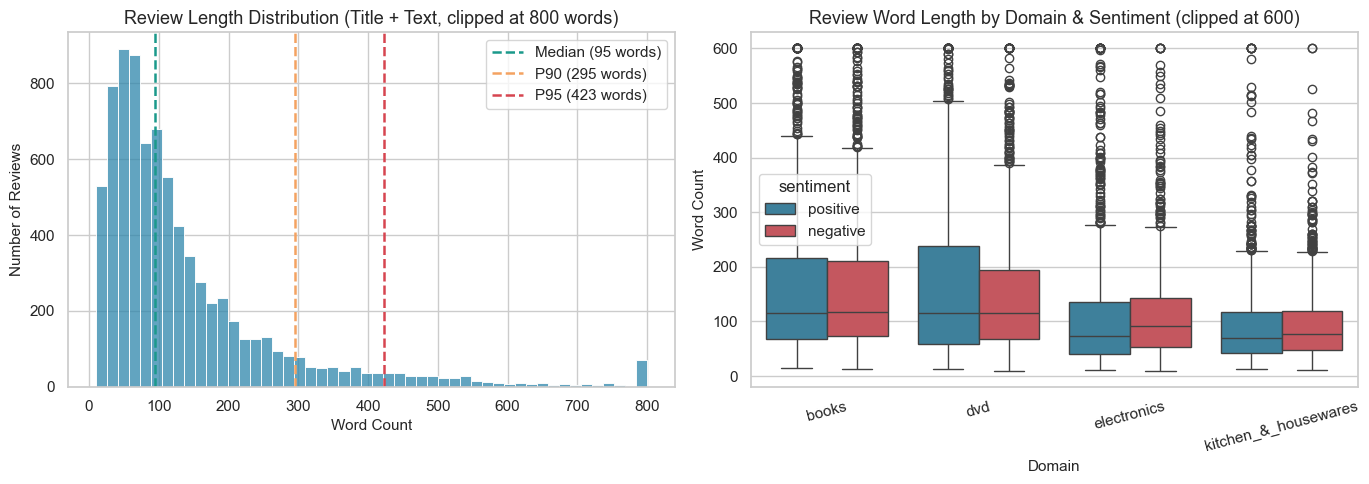

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

p50 = np.percentile(df["full_word_len"], 50)
p90 = np.percentile(df["full_word_len"], 90)
p95 = np.percentile(df["full_word_len"], 95)

sns.histplot(df["full_word_len"].clip(upper=800), bins=50, color="#2E86AB", ax=axes[0])
axes[0].axvline(p50, color="#1B998B", linestyle="--", linewidth=1.8, label=f"Median ({p50:.0f} words)")
axes[0].axvline(p90, color="#F4A261", linestyle="--", linewidth=1.8, label=f"P90 ({p90:.0f} words)")
axes[0].axvline(p95, color="#D64550", linestyle="--", linewidth=1.8, label=f"P95 ({p95:.0f} words)")
axes[0].set_title("Review Length Distribution (Title + Text, clipped at 800 words)")
axes[0].set_xlabel("Word Count")
axes[0].set_ylabel("Number of Reviews")
axes[0].legend()

sns.boxplot(
    data=df,
    x="domain",
    y=df["full_word_len"].clip(upper=600),
    hue="sentiment",
    palette={"positive": "#2E86AB", "negative": "#D64550"},
    ax=axes[1],
)
axes[1].set_title("Review Word Length by Domain & Sentiment (clipped at 600)")
axes[1].set_xlabel("Domain")
axes[1].set_ylabel("Word Count")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(FIG_DIR / "fig02_length_distributions.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Frequent Words & Bigrams (Sentiment vs. Domain Vocabulary)
Compare top unigrams and bigrams across Positive vs. Negative reviews and across all four product domains.

In [38]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

EXTRA_STOPS = {"don", "doesn", "didn", "ve", "ll", "re", "isn", "wasn", "won", "wouldn", "couldn", "shouldn", "aren", "haven", "hasn"}
CUSTOM_STOPS = sorted(ENGLISH_STOP_WORDS.union(EXTRA_STOPS))


def top_ngrams(texts: pd.Series, ngram_range=(1, 1), top_k=15) -> pd.DataFrame:
    vec = CountVectorizer(
        stop_words=CUSTOM_STOPS,
        ngram_range=ngram_range,
        min_df=3,
        token_pattern=r"(?u)\b[a-zA-Z]{2,}\b",
    )
    X = vec.fit_transform(texts)
    counts = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    top_idx = counts.argsort()[::-1][:top_k]
    return pd.DataFrame({"ngram": vocab[top_idx], "count": counts[top_idx]})


pos_unigrams = top_ngrams(df.loc[df["sentiment"] == "positive", "full_text"], (1, 1), 15)
neg_unigrams = top_ngrams(df.loc[df["sentiment"] == "negative", "full_text"], (1, 1), 15)
pos_bigrams = top_ngrams(df.loc[df["sentiment"] == "positive", "full_text"], (2, 2), 15)
neg_bigrams = top_ngrams(df.loc[df["sentiment"] == "negative", "full_text"], (2, 2), 15)

print("Top 15 Unigrams — Positive vs. Negative:")
display(
    pd.concat(
        [
            pos_unigrams.rename(columns={"ngram": "pos_unigram", "count": "pos_count"}),
            neg_unigrams.rename(columns={"ngram": "neg_unigram", "count": "neg_count"}),
        ],
        axis=1,
    )
)

print("\nTop 15 Bigrams — Positive vs. Negative:")
display(
    pd.concat(
        [
            pos_bigrams.rename(columns={"ngram": "pos_bigram", "count": "pos_count"}),
            neg_bigrams.rename(columns={"ngram": "neg_bigram", "count": "neg_count"}),
        ],
        axis=1,
    )
)

Top 15 Unigrams — Positive vs. Negative:


,pos_unigram,pos_count,neg_unigram,neg_count
0,book,2253,book,2558
1,great,2151,just,1836
2,good,1648,like,1707
3,like,1551,movie,1424
4,just,1472,good,1378
5,movie,1213,time,1255
6,time,1188,read,925
7,use,1085,really,924
8,film,1002,film,874
9,best,913,work,846



Top 15 Bigrams — Positive vs. Negative:


,pos_bigram,pos_count,neg_bigram,neg_count
0,highly recommend,150,waste money,171
1,read book,125,waste time,125
2,easy use,112,customer service,121
3,works great,98,read book,116
4,easy clean,91,save money,84
5,years ago,87,years ago,76
6,sound quality,82,does work,75
7,great product,80,reading book,75
8,long time,71,year old,71
9,year old,69,sound quality,66


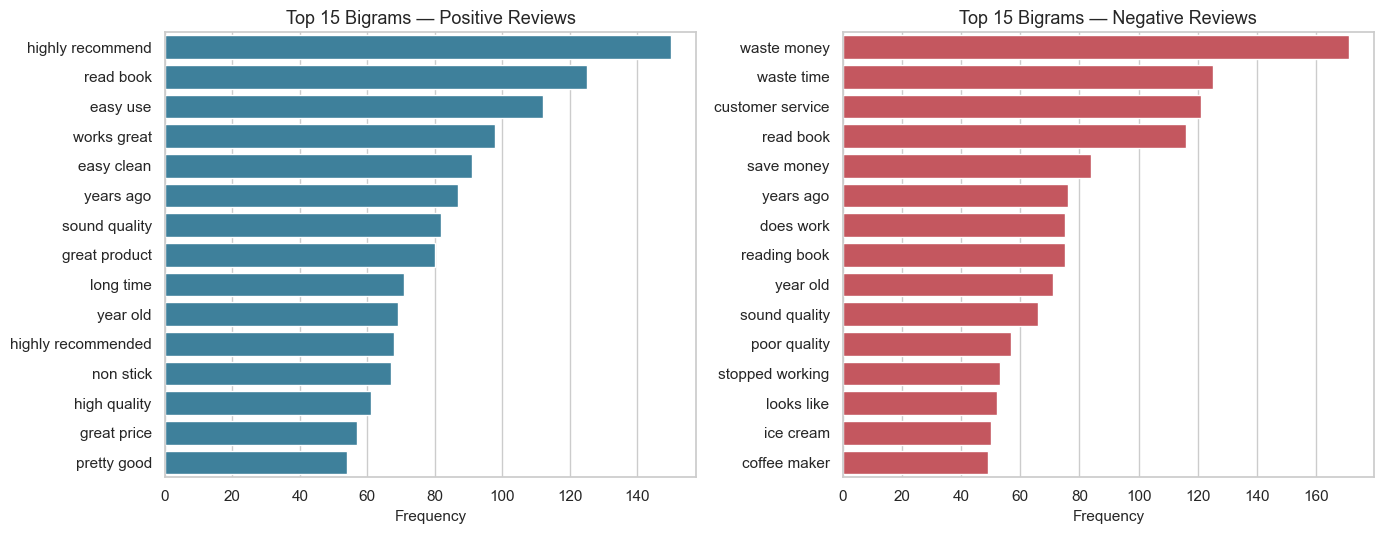


Top 10 Bigrams by Domain:


,books,dvd,electronics,kitchen_&_housewares
0,read book,great movie,sound quality,non stick
1,reading book,year old,customer service,easy clean
2,book read,good movie,works great,coffee maker
3,recommend book,years ago,easy use,customer service
4,great book,waste time,waste money,stainless steel
5,book book,read book,does work,ice cream
6,book just,movie just,dvd player,easy use
7,highly recommend,watch movie,battery life,waste money
8,book like,high school,tech support,cast iron
9,bought book,like movie,highly recommend,great product


In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

sns.barplot(data=pos_bigrams, y="ngram", x="count", color="#2E86AB", ax=axes[0])
axes[0].set_title("Top 15 Bigrams — Positive Reviews")
axes[0].set_xlabel("Frequency")
axes[0].set_ylabel("")

sns.barplot(data=neg_bigrams, y="ngram", x="count", color="#D64550", ax=axes[1])
axes[1].set_title("Top 15 Bigrams — Negative Reviews")
axes[1].set_xlabel("Frequency")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig(FIG_DIR / "fig03_top_bigrams_sentiment.png", dpi=150, bbox_inches="tight")
plt.show()

domain_bigram_tables = {
    d: top_ngrams(df.loc[df["domain"] == d, "full_text"], (2, 2), 10)["ngram"].tolist()
    for d in DOMAINS
}
print("\nTop 10 Bigrams by Domain:")
display(pd.DataFrame(domain_bigram_tables))

## 7. Outliers, Label Noise & Temporal Distribution
Audit ultra-short/ultra-long reviews, suspected sarcastic or mismatched labels, and review publication years (temporal bias).

Empty review_text rows:         0
Ultra-short reviews (<=5 wds):  3 (0.04%)
Very long reviews (>500 wds):   245 (3.06%)


,domain,sentiment,rating_num,title_clean,review_text_clean
245,books,positive,5.0,"If you own a business, you need to listen to t...",Period
560,books,positive,4.0,Book Purchase: On Killing: The Psychological C...,"Good Transaction, Thank you"
5218,electronics,negative,1.0,Want to donate your money to Ridata plus pay t...,Then buy these Ridata Disc



Positive-labeled reviews containing strong negative cues: 84


/var/folders/26/d86kc9x17392f698h6_8y4_r0000gn/T/ipykernel_47535/3522059288.py:14: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  & (df["review_text_clean"].str.lower().str.contains(neg_cue_pattern, regex=True))


,domain,rating_num,title_clean,review_text_clean
3,books,4.0,For lovers of Robicheaux,This book is for lovers of Robicheaux. His dem...
46,books,5.0,"Wonderful ""Wizard of Oz""","I was a reasonably big fan of the ""Wizard of O..."
80,books,5.0,this book rocks,this book sucks very badly! as soon as i was o...
88,books,5.0,witty and excellent,this book sucks you in from page one! it's ent...
91,books,5.0,Excellent narrative of Billy Beane and his bea...,Lewis has written a fascinating study of the b...



Review date range: 1997 to 2006


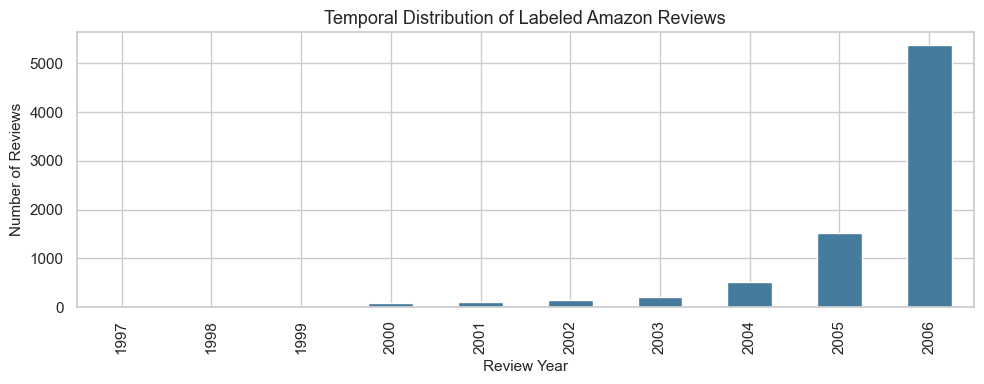

In [40]:
very_short = df[df["word_len"] <= 5]
very_long = df[df["word_len"] > 500]
empty_text = df[df["review_text_clean"] == ""]

print(f"Empty review_text rows:         {len(empty_text)}")
print(f"Ultra-short reviews (<=5 wds):  {len(very_short)} ({len(very_short)/len(df)*100:.2f}%)")
print(f"Very long reviews (>500 wds):   {len(very_long)} ({len(very_long)/len(df)*100:.2f}%)")

display(very_short[["domain", "sentiment", "rating_num", "title_clean", "review_text_clean"]].head(8))

neg_cue_pattern = r"\b(sucks|terrible|horrible|awful|waste of money|do not buy|worst)\b"
suspect_pos = df[
    (df["sentiment"] == "positive")
    & (df["review_text_clean"].str.lower().str.contains(neg_cue_pattern, regex=True))
]
print(f"\nPositive-labeled reviews containing strong negative cues: {len(suspect_pos)}")
display(suspect_pos[["domain", "rating_num", "title_clean", "review_text_clean"]].head(5))

year_counts = df["review_year"].value_counts().sort_index()
print(f"\nReview date range: {int(df['review_year'].min())} to {int(df['review_year'].max())}")

fig, ax = plt.subplots(figsize=(10, 4))
year_counts.plot(kind="bar", color="#457B9D", ax=ax)
ax.set_title("Temporal Distribution of Labeled Amazon Reviews")
ax.set_xlabel("Review Year")
ax.set_ylabel("Number of Reviews")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig04_temporal_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Deduplication & Processed CSV Exports
Export two processed versions of the cleaned, anonymized dataset so the team can compare or reproduce either stage cleanly:
1. `data/processed/amazon_reviews_with_duplicates.csv` — all **8,000** parsed, HTML-unescaped labeled reviews.
2. `data/processed/amazon_reviews_no_duplicates.csv` — **7,852** unique reviews after removing exact normalized `review_text` duplicates (`keep="first"`, after confirming **0** cross-sentiment conflicts).
3. `data/processed/dropped_duplicates_log.csv` — the **148** removed rows retained for auditability.

In [41]:
# 1. Confirm zero label conflicts before deduplicating
conflicts = df.groupby("norm_text")["label"].nunique()
assert (conflicts > 1).sum() == 0, "Conflicting sentiment labels found in duplicates!"

handoff_cols = [
    "review_id",
    "domain",
    "sentiment",
    "label",
    "title_clean",
    "review_text_clean",
    "full_text",
]

# 2. Export full processed dataset (WITH duplicates — 8,000 rows)
df_with_dups = df.reset_index(drop=True).copy()
df_with_dups.insert(0, "review_id", range(len(df_with_dups)))
with_dups_path = PROCESSED_DIR / "amazon_reviews_with_duplicates.csv"
df_with_dups[handoff_cols].to_csv(with_dups_path, index=False, encoding="utf-8")

# 3. Save audit log of dropped duplicates (148 rows)
dropped_df = df[df.duplicated(subset=["norm_text"], keep="first")].copy()
dropped_log_path = PROCESSED_DIR / "dropped_duplicates_log.csv"
dropped_df[["domain", "sentiment", "unique_id", "title_clean", "review_text_clean"]].to_csv(
    dropped_log_path, index=False, encoding="utf-8"
)

# 4. Export deduplicated dataset (NO duplicates — 7,852 rows)
df_no_dups = (
    df.drop_duplicates(subset=["norm_text"], keep="first")
    .reset_index(drop=True)
    .copy()
)
df_no_dups.insert(0, "review_id", range(len(df_no_dups)))
no_dups_path = PROCESSED_DIR / "amazon_reviews_no_duplicates.csv"
df_no_dups[handoff_cols].to_csv(no_dups_path, index=False, encoding="utf-8")

# Before vs. after audit table
before_ct = pd.crosstab(df["domain"], df["sentiment"])
after_ct = pd.crosstab(df_no_dups["domain"], df_no_dups["sentiment"])
dedup_audit = pd.DataFrame(
    {
        "pos_before": before_ct["positive"],
        "pos_after": after_ct["positive"],
        "neg_before": before_ct["negative"],
        "neg_after": after_ct["negative"],
        "dropped": (before_ct.sum(axis=1) - after_ct.sum(axis=1)),
    }
)
display(dedup_audit)

print(f"With duplicates: {len(df_with_dups):,} rows -> {with_dups_path}")
print(f"No duplicates:   {len(df_no_dups):,} rows -> {no_dups_path}")
print(f"Dropped log:     {len(dropped_df):,} rows -> {dropped_log_path}")

,pos_before,pos_after,neg_before,neg_after,dropped
domain,,,,,
books,1000,993,1000,963,44
dvd,1000,995,1000,959,46
electronics,1000,987,1000,978,35
kitchen_&_housewares,1000,996,1000,981,23


With duplicates: 8,000 rows -> /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/data/processed/amazon_reviews_with_duplicates.csv
No duplicates:   7,852 rows -> /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/data/processed/amazon_reviews_no_duplicates.csv
Dropped log:     148 rows -> /Users/andresvargas/Documents/Torrens MRS/503/assesment3_is/data/processed/dropped_duplicates_log.csv
